# Reproducing the published neural network: its seeds, its widths and what its hold-out score is worth

**Question:** Can the published network be reproduced, and does its width matter when a whole campaign is held out?

**Level 3: State of the art** · Needs: 05-learned-arms/01-fitting-a-learned-arm-on-nine-sites, 05-learned-arms/02-every-arm-and-why-each-one-refuses · Reading time: about 40 minutes

## Objectives

Kulatilake, Hudaverdi and Wu 2012 trained a small neural network on this corpus and reported it as the best of three predictors on a 12-blast hold-out. The engine implements the network to its published specification. This notebook asks two questions of that result. Can the network be reproduced, and what is the published score worth once the random initialisation is varied? And does the hidden width the authors chose matter when a whole campaign is held out?

By the end you will have:

- routed the 12 hold-out blasts to their stiffness group with the published discriminant and trained the engine's network on the corpus;
- compared the reproduced predictions with the printed column and with the measurements, blast by blast;
- retrained the network under 30 seeds and placed the printed score among them;
- repeated the authors' width selection and then scored six widths and the published pair with each campaign held out in turn.

## Setup

Install the packages with the exact pins of `notebooks/requirements.txt`. The engine is `blastfrag`, published on PyPI; the other packages are its numerical base and the plotting library.

```bash
pip install blastfrag==0.4.0 numpy==2.5.4 matplotlib==3.11.2
```

The setup cell imports the packages and the network class, `PublishedNeuralNetwork`, prints the versions, loads the corpus and the 12-blast hold-out of the 2012 paper (`protocol="2012"`), and defines `Table`. It imports `json` for the one reproduction check at the end.

In [1]:
# Imports, package versions and the corpus loader
from importlib.metadata import version
from pathlib import Path
import json

from blastfrag.learned import PublishedNeuralNetwork

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np

for name in ("blastfrag", "numpy", "matplotlib"):
    print(f"{name}=={version(name)}")

DERIVED = Path("../../../data/derived")
train = bf.load_training_corpus()
print(len(train), "blasts from", len({b.site for b in train}), "campaigns")

class Table:
    """Rows under a header, shown as a Markdown table"""

    def __init__(self, header, rows):
        self.header = list(header)
        self.rows = [[str(cell) for cell in row] for row in rows]

    def _repr_markdown_(self):
        lines = ["| " + " | ".join(self.header) + " |", "|" + "---|" * len(self.header)]
        lines += ["| " + " | ".join(row) + " |" for row in self.rows]
        return "\n".join(lines)

    __repr__ = _repr_markdown_

holdout = bf.load_holdout(protocol="2012")

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2
97 blasts from 10 campaigns


## Data

| Source | Owner and URL | Licence class | File the notebook reads |
|---|---|---|---|
| The 97 training blasts and the 12-blast hold-out with the network's printed predictions | Kulatilake, Hudaverdi and Wu 2012, https://doi.org/10.1007/s10706-012-9496-3; Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 | numeric facts reused with citation; the articles never ship | the corpus and `bf.load_holdout(protocol="2012")` inside the `blastfrag` wheel |
| The seed sweep the offline bake wrote, for the one reproduction check | this repository (MIT), written by the offline bake | the product's own licence | `data/derived/benchmark.json`, field `network_seed_sweep` |

The hold-out includes the blast `Rc1`, which is also a training blast: the engine carries that leakage flag on the record, and the printed score is the one the paper reports, with that blast in.

## Method

The network of Kulatilake et al. 2012 (https://doi.org/10.1007/s10706-012-9496-3, section 5) is specified fully enough to reproduce:

- one network per rock-stiffness group, each trained on the rows of that group only; the group of a blast comes from the discriminant function published by Hudaverdi et al. 2010 (https://doi.org/10.1002/nag.957) and not from the corpus label, so a blast the corpus never saw is routed the same way;
- seven inputs, one hidden layer with a logistic activation, one output, and min-max normalisation of inputs and target (their Eq. 11);
- Levenberg-Marquardt training, eight simulations per width averaged, and a hidden width swept from 6 to 15 and chosen on the hold-out by RMSE and correlation, which gave 9 for the first group and 7 for the second.

Two properties follow from this specification and matter below. The width is chosen on the same 12 blasts on which the network is then scored, and the weights depend on a random initialisation that the paper does not report. The score used throughout is `r2_identity`, the variance explained about the 1:1 line.

### Step 1: route the blasts to their group

`assign_group` applies the published discriminant to a blast, and `discriminant_score` gives the score behind the decision: above the boundary a blast belongs to the high-modulus group 1, below it to group 2. The cell counts the training blasts of each group and routes the 12 hold-out blasts.

In [2]:
# Route the 12 hold-out blasts and count the training blasts of each stiffness group
groups = [bf.assign_group(blast) for blast in train]
print("training blasts by group (1 = high modulus, 2 = low):", {g: groups.count(g) for g in (1, 2)})
rows = [(b.blast_id, b.site, f"{b.E_GPa:.1f}", f"{bf.discriminant_score(b):+.2f}", bf.assign_group(b),
    b.group) for b in holdout]
Table(["blast", "campaign", "E (GPa)", "discriminant score", "routed to", "corpus label"], rows)

training blasts by group (1 = high modulus, 2 = low): {1: 35, 2: 62}


| blast | campaign | E (GPa) | discriminant score | routed to | corpus label |
|---|---|---|---|---|---|
| En13 | Enusa | 60.0 | +17.69 | 1 | 1 |
| Ru7 | Reocin-UG | 45.0 | +15.17 | 1 | 1 |
| Mg8 | Murgul | 50.0 | +13.88 | 1 | 1 |
| Mg9 | Murgul | 50.0 | +13.06 | 1 | 1 |
| Rc1 | Reocin | 45.0 | +15.11 | 1 | 1 |
| Mr12 | Mrica | 32.0 | +8.40 | 2 | 2 |
| Db10 | Dongri-Buzurg | 9.6 | +6.36 | 2 | 2 |
| Sm8 | Soma | 13.2 | +7.28 | 2 | 2 |
| Oz8 | Ozmert | 15.0 | +7.58 | 2 | 2 |
| Oz9 | Ozmert | 15.0 | +6.67 | 2 | 2 |
| Ad23 | Akdaglar | 16.9 | +6.76 | 2 | 2 |
| Ad24 | Akdaglar | 16.9 | +8.75 | 2 | 2 |

**What the output shows.** The corpus holds 35 high-modulus blasts and 62 low-modulus ones, so group 1 is trained on barely more than a third of the data. The discriminant sends the five hold-out blasts with a modulus of 45 GPa or more (Enusa, Reocin-UG, Murgul and Reocin) to group 1, and the seven with 32 GPa or less to group 2, with scores between 6.36 and 8.75 for group 2 and between 13.06 and 17.69 for group 1. It agrees with the corpus label in all twelve. **What it does not show:** how close a new blast can sit to the boundary; none of these twelve does.

### Step 2: reproduce the printed predictions

The cell trains the engine's reproduction once, with seed 0, on the whole corpus and predicts the 12 blasts. It scores the result and the printed column of the paper, and also the other two predictors the paper prints, a regression and a Kuz-Ram column, so that the claim "best of three" can be checked.

In [3]:
# Fit the engine's reproduction once (seed 0) and set it beside the printed column and the measurements
network = PublishedNeuralNetwork(seed=0).fit(train)
reproduced = network.predict(holdout)
printed = [bf.Prediction(method="published", blast_id=b.blast_id,
    x50_m=b.meta["published"]["nn_mean_2012"]) for b in holdout]
published_score = bf.score(holdout, printed)
seed0_score = bf.score(holdout, reproduced)
rows = [(b.blast_id, f"{b.x50_m:.2f}", f"{q.x50_m:.2f}", f"{p.x50_m:.3f}") for b, q,
    p in zip(holdout, printed, reproduced)]
other_columns = {}
for key in ("regression_2012", "kuzram_2012"):
    column = [bf.Prediction(method=key, blast_id=b.blast_id, x50_m=b.meta["published"][key]) for b in holdout]
    other_columns[key] = bf.score(holdout, column).r2_identity
print("printed r2 of the other two predictors of the paper:", {k: round(v, 3) for k, v in other_columns.items()})
print(f"r2 printed column = {published_score.r2_identity:.3f} (RMSE {published_score.rmse_m:.3f} m) | "
      f"r2 reproduced, seed 0 = {seed0_score.r2_identity:.3f} (RMSE {seed0_score.rmse_m:.3f} m)")
Table(["blast", "measured (m)", "printed (m)", "reproduced (m)"], rows)

printed r2 of the other two predictors of the paper: {'regression_2012': 0.708, 'kuzram_2012': 0.232}
r2 printed column = 0.910 (RMSE 0.044 m) | r2 reproduced, seed 0 = 0.309 (RMSE 0.121 m)


| blast | measured (m) | printed (m) | reproduced (m) |
|---|---|---|---|
| En13 | 0.47 | 0.42 | 0.419 |
| Ru7 | 0.64 | 0.63 | 0.428 |
| Mg8 | 0.44 | 0.37 | 0.374 |
| Mg9 | 0.25 | 0.28 | 0.255 |
| Rc1 | 0.46 | 0.43 | 0.460 |
| Mr12 | 0.20 | 0.12 | 0.160 |
| Db10 | 0.35 | 0.33 | 0.687 |
| Sm8 | 0.18 | 0.19 | 0.190 |
| Oz8 | 0.23 | 0.15 | 0.136 |
| Oz9 | 0.17 | 0.19 | 0.180 |
| Ad23 | 0.21 | 0.21 | 0.225 |
| Ad24 | 0.20 | 0.19 | 0.211 |

The next cell plots the measured size against what the paper printed (green circles) and against what the engine reproduced (orange squares), with the 1:1 line for reference. Look at how close each set of points is to the line and which blasts the reproduction misses most.

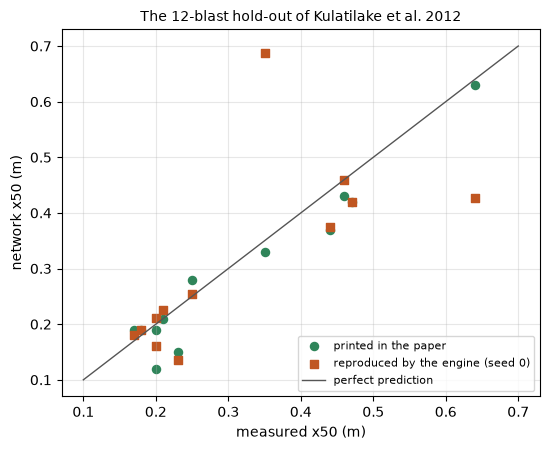

In [4]:
# Measured against printed and reproduced size on the 12 hold-out blasts
measured = np.array([b.x50_m for b in holdout])
fig, ax = plt.subplots(figsize=(5.6, 4.6))
ax.scatter(measured, [q.x50_m for q in printed], s=34, color="#2f855a", label="printed in the paper")
ax.scatter(measured, [p.x50_m for p in reproduced], s=34, marker="s", color="#c05621",
    label="reproduced by the engine (seed 0)")
ax.plot([0.1, 0.7], [0.1, 0.7], color="#555", lw=1, label="perfect prediction")
ax.set_xlabel("measured x50 (m)")
ax.set_ylabel("network x50 (m)")
ax.set_title("The 12-blast hold-out of Kulatilake et al. 2012", fontsize=10)
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

**What the figure shows.** The printed column (green circles) hugs the 1:1 line: its r2 is 0.910 and its RMSE 0.044 m, against 0.708 for the paper's regression and 0.232 for its Kuz-Ram column, so the network is indeed the best of the three printed predictors. The reproduction (orange squares) follows the same trend but with visible misses, r2 0.309 and RMSE 0.121 m, the largest at Db10 (0.687 m predicted for a measured 0.35 m, where the paper prints 0.33 m) and at Ru7 (0.428 m for 0.64 m). **What it does not show:** which of the two is the typical network. One seed is one draw, and the next cells draw 30. **What follows:** the specification does not by itself reproduce the printed score.

## State of the art

The state of the art for this predictor is the paper itself, and what it establishes is narrower than a reader of its abstract might assume.

- **Kulatilake, Hudaverdi and Wu 2012** (https://doi.org/10.1007/s10706-012-9496-3) is the reference for the network: the specification of the Method section and a hold-out of 12 blasts on which it is the best of three printed predictors (step 2).
- The network is reported as one trained instance. The paper gives no spread over the weight initialisation, so the printed score is a single draw.
- The hidden width is chosen on the same 12 blasts used to score the network, so the score is an optimum over widths on its own test set.
- No campaign is held out: the 12 blasts come from nine of the ten campaigns that also supply the training rows.

The three steps below test each limit with the engine: the seed (step 3), the width selection (step 4) and the campaign held out (step 5).

### Step 3: the seed

Training starts from random weights, and `seed` fixes them. The cell retrains the whole network 30 times with seeds 0 to 29, scores the 12-blast hold-out each time and summarises the 30 scores with `summarise_draws`. It takes about half a minute.

In [5]:
# Retrain the network under 30 weight-initialisation seeds and score the 12-blast hold-out each time, about half a
# minute
seed_scores = []
for seed in range(30):
    trained = PublishedNeuralNetwork(seed=seed).fit(train)
    seed_scores.append(bf.score(holdout, trained.predict(holdout)).r2_identity)
seed_scores = np.sort(seed_scores)
summary = bf.summarise_draws(list(seed_scores))
print(f"printed column r2 = {published_score.r2_identity:.3f}")
print("30 reproduced seeds:", f"min {seed_scores.min():.3f} | p25 {summary['p25']:.3f}",
      f"| median {summary['median']:.3f} | p75 {summary['p75']:.3f} | max {seed_scores.max():.3f}")
print("seeds that reach the printed score:", int((seed_scores >= published_score.r2_identity).sum()))

printed column r2 = 0.910
30 reproduced seeds: min 0.167 | p25 0.299 | median 0.340 | p75 0.462 | max 0.636
seeds that reach the printed score: 0


The next cell draws the 30 scores on one axis, with the printed score as an orange line and the median of the seeds as a dashed line. All the information is in the horizontal position: look for the place of the orange line among the blue points.

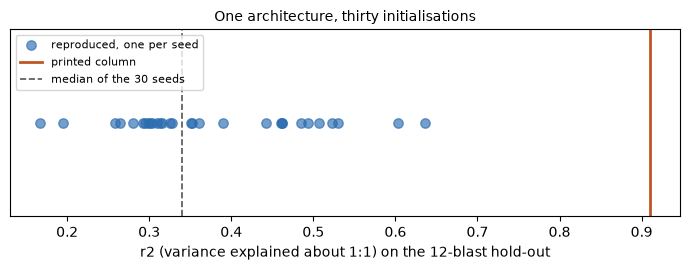

In [6]:
# The 30 reproduced scores as a strip, with the printed score as a vertical line
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.scatter(seed_scores, np.zeros(len(seed_scores)), s=46, alpha=0.65, color="#2b6cb0",
    label="reproduced, one per seed")
ax.axvline(published_score.r2_identity, color="#c05621", lw=2, label="printed column")
ax.axvline(np.median(seed_scores), color="#555", lw=1.2, ls="--", label="median of the 30 seeds")
ax.set_yticks([])
ax.set_xlabel("r2 (variance explained about 1:1) on the 12-blast hold-out")
ax.set_title("One architecture, thirty initialisations", fontsize=10)
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

**What the figure shows.** The 30 reproduced scores lie between 0.167 and 0.636, with a median of 0.340 and a middle half between 0.299 and 0.462, and none of them reaches the printed 0.910 (the orange line, far to the right). The seed alone moves the network's hold-out score over a range about as wide as the gap between the paper's regression (0.708) and its Kuz-Ram column (0.232). **What it does not show:** that the authors misreported the network: a favourable initialisation exists in principle, and the paper may have chosen among several. **What follows:** the printed score is a property of one trained instance that the specification does not reproduce, not a property of the architecture, and 0 of 30 seeds recover it.

### Step 4: the width selection

`sweep_hidden_width` repeats the authors' procedure: for each width from 6 to 15 it trains the network and scores the hold-out rows of each group, and picks the width with the lowest RMSE. The cell prints the width it picks beside the published one and the best and the worst RMSE of each group, and the figure draws the whole RMSE curve. It takes about a minute.

In [7]:
# Repeat the source's width selection: train every width from 6 to 15, about one minute
sweep = PublishedNeuralNetwork(n_simulations=8, seed=0).sweep_hidden_width(train, holdout)
rows = []
for group, entry in sweep.items():
    best = min(entry["table"], key=lambda r: r["rmse"])
    worst = max(entry["table"], key=lambda r: r["rmse"])
    rows.append((group, entry["published_optimum"], entry["best_hidden"], f"{best['rmse']:.3f}",
        f"{worst['rmse']:.3f}", worst["hidden"]))
Table(["group", "published width", "width picked here", "best RMSE (m)", "worst RMSE (m)", "worst width"], rows)

| group | published width | width picked here | best RMSE (m) | worst RMSE (m) | worst width |
|---|---|---|---|---|---|
| 1 | 9 | 8 | 0.037 | 0.109 | 13 |
| 2 | 7 | 11 | 0.106 | 0.157 | 12 |

The next cell draws, for each stiffness group, the RMSE of the network on the hold-out as a function of the hidden width, with the published choice in orange and the choice of this reproduction in green. Look at how irregular the curves are and at the distance between the two vertical lines.

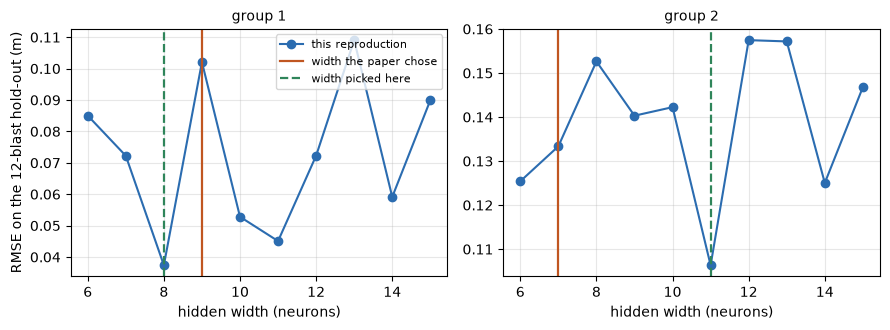

In [8]:
# RMSE on the hold-out against hidden width, one line per stiffness group
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=False)
for ax, (group, entry) in zip(axes, sweep.items()):
    widths = [r["hidden"] for r in entry["table"]]
    ax.plot(widths, [r["rmse"] for r in entry["table"]], "o-", color="#2b6cb0", label="this reproduction")
    ax.axvline(entry["published_optimum"], color="#c05621", lw=1.6, label="width the paper chose")
    ax.axvline(entry["best_hidden"], color="#2f855a", lw=1.6, ls="--", label="width picked here")
    ax.set_title(f"group {group}", fontsize=10)
    ax.set_xlabel("hidden width (neurons)")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("RMSE on the 12-blast hold-out (m)")
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

**What the figure shows.** The selection does not land on the published widths. For group 1 it picks width 8 (RMSE 0.037 m) where the paper chose 9; for group 2 it picks width 11 (RMSE 0.106 m) where the paper chose 7. The curves are jagged: in group 1 the RMSE goes from 0.037 m at width 8 to 0.109 m at width 13, and neighbouring widths differ by as much as the extremes, so the optimum is the lowest point of a noisy curve fitted on 5 and 7 blasts rather than a clear minimum. **What it does not show:** that either choice is better outside the hold-out. **What follows:** the width is a number tuned on the test set, so the printed score is optimistic by construction, and the next step asks whether any width transfers to a campaign it has not seen.

### Step 5: the width with a campaign held out

The protocol of the product holds each of the ten campaigns out in turn and trains a fresh network on the other nine. The cell does that for the published pair of widths (9, 7) and for six widths used in both groups, from 6 to 11, pools the 97 out-of-fold predictions of each setting and scores them, with the null (the training mean) for reference. It trains 70 networks and takes about two minutes.

In [9]:
# Leave-one-site-out for six widths and the published pair; every fold trains a fresh network, about two minutes
folds = list(bf.leave_one_site_out(train))
tested = [blast for fold in folds for blast in fold.test]
published = PublishedNeuralNetwork(hidden=dict(bf.PUBLISHED_NETWORK_WIDTHS))
pair = [p for fold in folds for p in published.fit(fold.train).predict(fold.test)]
pair_score = bf.score(tested, pair)
held_out = {}
for width in range(6, 12):
    predicted = [p for fold in folds for p in PublishedNeuralNetwork(hidden={1: width,
        2: width}).fit(fold.train).predict(fold.test)]
    held_out[width] = bf.score(tested, predicted)
null_score = bf.score(tested, [p for fold in folds for p in bf.NullModel().fit(fold.train).predict(fold.test)])
rows = [(f"{width}, {width}", f"{s.r2_identity:.3f}", f"{s.rmse_m:.3f}") for width, s in held_out.items()]
rows += [("published (9, 7)", f"{pair_score.r2_identity:.3f}", f"{pair_score.rmse_m:.3f}")]
rows += [("null", f"{null_score.r2_identity:.3f}", f"{null_score.rmse_m:.3f}")]
Table(["widths (group 1, group 2)", "r2", "RMSE (m)"], rows)

| widths (group 1, group 2) | r2 | RMSE (m) |
|---|---|---|
| 6, 6 | -0.605 | 0.237 |
| 7, 7 | -0.653 | 0.241 |
| 8, 8 | -0.626 | 0.239 |
| 9, 9 | -0.586 | 0.236 |
| 10, 10 | -0.902 | 0.258 |
| 11, 11 | -0.568 | 0.235 |
| published (9, 7) | -0.626 | 0.239 |
| null | -0.216 | 0.207 |

The next cell draws the held-out score of each width as a blue line, with the published pair as an orange line and the null as a dashed line. The dashed line is the bar to clear: look at whether any point of the blue line gets above it.

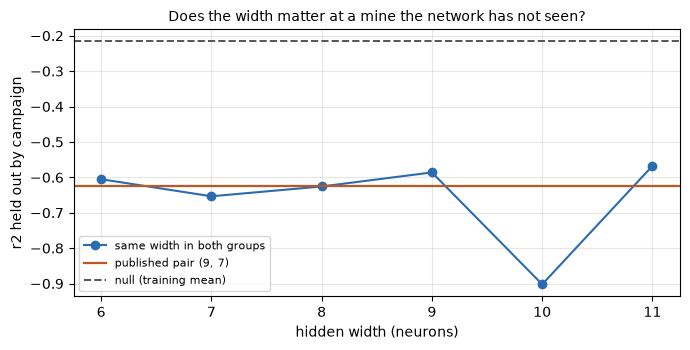

In [10]:
# Held-out score against hidden width, beside the published pair and the null
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(list(held_out), [s.r2_identity for s in held_out.values()], "o-", color="#2b6cb0",
    label="same width in both groups")
ax.axhline(pair_score.r2_identity, color="#c05621", lw=1.6, label="published pair (9, 7)")
ax.axhline(null_score.r2_identity, color="#555", ls="--", lw=1.4, label="null (training mean)")
ax.set_xlabel("hidden width (neurons)")
ax.set_ylabel("r2 held out by campaign")
ax.set_title("Does the width matter at a mine the network has not seen?", fontsize=10)
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

**What the figure shows.** Every width scores below the null (the dashed line at -0.216). The six widths sit between -0.568 (width 11) and -0.902 (width 10), and the published pair (9, 7), the orange line, scores -0.626, in the middle of that band. The RMSE barely moves with the width, from 0.235 m to 0.258 m, against 0.207 m for the null. The curve is not monotonic: width 10 is the worst and width 11 the best, two adjacent widths, which is again the instability seen in step 4. **What it does not show:** that no network could transfer, only that this architecture on the training rows of these folds does not, at any width tried. **What follows:** tuning the width on a hold-out of the same campaigns buys nothing at a campaign it has not seen.

### Reproduction check: the seed sweep of the bake

The 30 seed scores of step 3 are the ones the offline bake wrote into `benchmark.json`, so they must be equal. The cell prints the largest difference.

In [11]:
# The one reproduction check: the 30 seed scores equal the sweep the bake wrote
benchmark = json.loads((DERIVED / "benchmark.json").read_text(encoding="utf-8"))
baked = benchmark["network_seed_sweep"]["r2_identity"]
print("largest difference to the baked seed sweep:", f"{np.max(np.abs(np.sort(baked) - seed_scores)):.1e}")

largest difference to the baked seed sweep: 0.0e+00


## Results

**Answer:** the published network can be reproduced to its specification but not to its score, and its width does not matter when a campaign is held out because no width helps. The printed network scores r2 0.910 on the 12-blast hold-out; the engine's reproduction scores 0.309 with seed 0, and over 30 seeds the score runs from 0.167 to 0.636 with a median of 0.340, so 0 of 30 reach the printed value. Repeating the authors' width selection picks 8 and 11 where they chose 9 and 7, on RMSE curves that move from 0.037 m to 0.109 m between widths of one group. With each of the ten campaigns held out in turn, the published pair scores -0.626 (RMSE 0.239 m), the six widths from 6 to 11 between -0.568 and -0.902, and the null -0.216 (RMSE 0.207 m): no width reaches the null.

So the published score is the best of several things at once: a favourable initialisation, a width tuned on the test blasts and a hold-out whose campaigns are also in training. Each removes some of its meaning, and the product reports the held-out figure instead.

**What this does not show.** It does not show that the authors made a mistake: one initialisation can beat the median of many, and they may have chosen among several. It does not show that no neural network can predict a new campaign; the network tested here is the published one, on 97 rows. And the 30 seeds and the 70 networks are a bounded experiment, not a distribution of every possible training run.

## Summary

- The network is routed by the published discriminant (35 and 62 training blasts per group) and reproduced from its specification; with seed 0 it scores 0.309 on the hold-out where the paper prints 0.910.
- Over 30 seeds the score runs from 0.167 to 0.636, and none reaches the printed value; the width selection picks 8 and 11 against the published 9 and 7.
- With each campaign held out, every width scores between -0.568 and -0.902, below the null at -0.216, and the published pair gets -0.626.
- Next: topic 06 asks how a prediction responds when the design changes.

## References

- Kulatilake, Hudaverdi and Wu 2012, https://doi.org/10.1007/s10706-012-9496-3 (the back-propagation network and its hold-out)
- Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 (the corpus and the published regression)
- `blastfrag` 0.4.0, the engine, on PyPI: https://pypi.org/project/blastfrag/